# QSAR Solubility Prediction

Predicting the water solubility of molecules using the ESOL dataset, RDKit molecular descriptors, and Random Forest.

## Dataset
1144 molecules (Delaney solubility dataset)

## Method
- Calculation of 6 descriptors using RDKit (MolWt, LogP, NumHDonors,
  NumHAcceptors, NumRotatableBonds, TPSA)
- Random Forest Regressor (100 trees)

## Result
- R² Score: 0.901 (test set)
- Cross-validation R²: 0.913
- Most important feature: LogP (81% importance)

In [2]:
! pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.2/37.2 MB 40.1 MB/s eta 0:00:00


In [3]:
import pandas as pd

from rdkit import Chem
from rdkit.Chem import Descriptors

import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

In [4]:
url = "https://raw.githubusercontent.com/dataprofessor/data/master/delaney.csv"
df = pd.read_csv(url)

In [5]:
def calculate_descriptors(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None
    return {
        'MolWt': Descriptors.MolWt(mol),
        'LogP': Descriptors.MolLogP(mol),
        'NumHDonors': Descriptors.NumHDonors(mol),
        'NumHAcceptors': Descriptors.NumHAcceptors(mol),
        'NumRotatableBonds': Descriptors.NumRotatableBonds(mol),
        'TPSA': Descriptors.TPSA(mol)
    }

In [6]:
descriptors_list = []


for smiles in df['SMILES']:
  desc = calculate_descriptors(smiles)
  descriptors_list.append(desc)

desc_df = pd.DataFrame(descriptors_list)
final_df = pd.concat([df, desc_df], axis=1)

print(desc_df.isnull().sum().sum())
final_df.head()

0


,Compound ID,measured log(solubility:mol/L),ESOL predicted log(solubility:mol/L),SMILES,MolWt,LogP,NumHDonors,NumHAcceptors,NumRotatableBonds,TPSA
0,"1,1,1,2-Tetrachloroethane",-2.18,-2.794,ClCC(Cl)(Cl)Cl,167.850,2.5954,0,0,0,0.0
1,"1,1,1-Trichloroethane",-2.00,-2.232,CC(Cl)(Cl)Cl,133.405,2.3765,0,0,0,0.0
2,"1,1,2,2-Tetrachloroethane",-1.74,-2.549,ClC(Cl)C(Cl)Cl,167.850,2.5938,0,0,1,0.0
3,"1,1,2-Trichloroethane",-1.48,-1.961,ClCC(Cl)Cl,133.405,2.0289,0,0,1,0.0
4,"1,1,2-Trichlorotrifluoroethane",-3.04,-3.077,FC(F)(Cl)C(F)(Cl)Cl,187.375,2.9189,0,0,1,0.0


In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

x = final_df[['MolWt', 'LogP', 'NumHDonors', 'NumHAcceptors', 'NumRotatableBonds', 'TPSA']]
y = final_df['measured log(solubility:mol/L)']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(x_train, y_train)

predictions = model.predict(x_test)

score = r2_score(y_test, predictions)
print(f"R² Score: {score:.3f}")

R² Score: 0.901


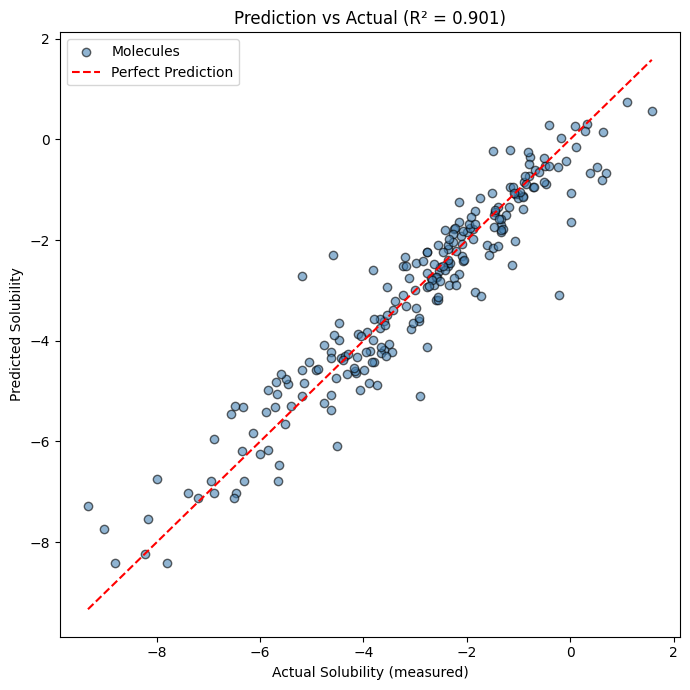

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))
plt.scatter(y_test, predictions , alpha=0.6, color='steelblue', edgecolors='k', label='Molecules')

min_val = min(min(y_test), min(predictions))
max_val = max(max(y_test), max(predictions))

plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect Prediction')

plt.xlabel('Actual Solubility (measured)')
plt.ylabel('Predicted Solubility')
plt.title(f'Prediction vs Actual (R² = {score:.3f})')
plt.legend()
plt.tight_layout()
plt.show()

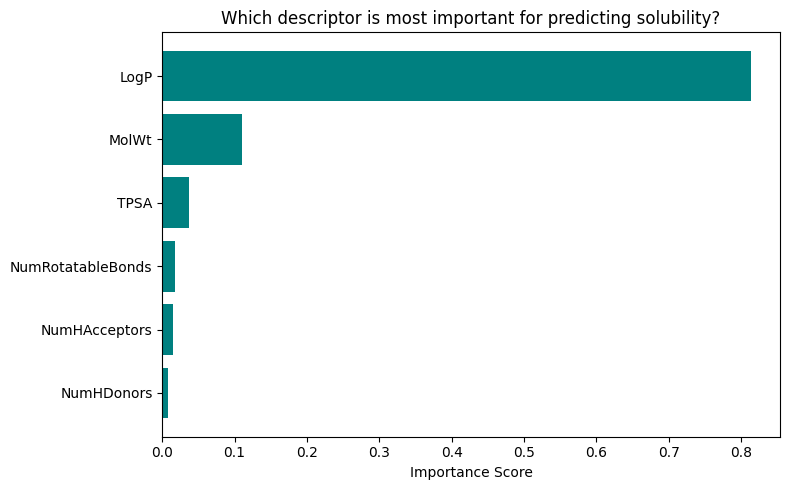



LogP: 0.813
MolWt: 0.110
TPSA: 0.036
NumRotatableBonds: 0.018
NumHAcceptors: 0.014
NumHDonors: 0.008


In [9]:
importances = model.feature_importances_
features = ['MolWt', 'LogP', 'NumHDonors', 'NumHAcceptors', 'NumRotatableBonds', 'TPSA']

sorted_idx = importances.argsort()[::-1]

# sorted_features = [features[i] for i in sorted_idx]
sorted_features = []
for i in sorted_idx:
    sorted_features.append(features[i])

sorted_importances = importances[sorted_idx]

plt.figure(figsize=(8, 5))
plt.barh(sorted_features, sorted_importances, color='teal')
plt.xlabel('Importance Score')
plt.title('Which descriptor is most important for predicting solubility?')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
print("\n")
for name, score in zip(sorted_features, sorted_importances):
    print(f"{name}: {score:.3f}")